# 用户分层分析

根据用户的登录、购买、消费和浏览情况计算得分，并按规则划分用户类型。标记购买频次为 0 但累计消费大于 0 的 85 名用户，比较排除这些记录前后的分层结果。


In [15]:
# 1. 环境准备与库导入
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [16]:
# 2. 本地数据和输出路径
from pathlib import Path

project_dir = Path.cwd()
if project_dir.name == 'code':
    project_dir = project_dir.parent
input_path = project_dir / 'data' / 'user_personalized_features.csv'
output_dir = project_dir / 'outputs' / 'improved'
output_dir.mkdir(parents=True, exist_ok=True)
print('数据文件存在', input_path.exists())
print('输出文件夹', output_dir)


数据文件存在 True
输出文件夹 C:\Users\86156\Documents\ChatGPT\sql\电商用户分层项目_跟做包\outputs\improved


In [17]:
# 3. 数据加载与预处理函数
def load_and_preprocess(filepath):
    """数据加载与预处理"""
    df = pd.read_csv(filepath)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed:')].copy()
    
    # 数据质量检查
    print("=" * 60)
    print("第一阶段：数据质量检查")
    print("=" * 60)
    print(f"数据规模: {df.shape[0]} 行 x {df.shape[1]} 列")
    print(f"缺失值: {df.isnull().sum().sum()}")
    
    # 异常值处理
    age_outliers = df[(df['Age'] < 10) | (df['Age'] > 100)].shape[0]
    print(f"年龄异常值: {age_outliers}")    
    return df

# 执行数据加载
df = load_and_preprocess(input_path)

# 标记购买频次与累计消费需要核对的记录
df['Needs_Review'] = (
    (df['Purchase_Frequency'] == 0)
    & (df['Total_Spending'] > 0)
)
print('需要核对口径的人数', int(df['Needs_Review'].sum()))

# 保存原始字段，用于排除后的重算
raw_df = df.copy()
df.head()

第一阶段：数据质量检查
数据规模: 1000 行 x 14 列
缺失值: 0
年龄异常值: 0
需要核对口径的人数 85


,User_ID,Age,Gender,Location,Income,Interests,Last_Login_Days_Ago,Purchase_Frequency,Average_Order_Value,Total_Spending,Product_Category_Preference,Time_Spent_on_Site_Minutes,Pages_Viewed,Newsletter_Subscription,Needs_Review
0,#1,56,Male,Suburban,38037,Sports,5,7,18,2546,Books,584,38,True,False
1,#2,46,Female,Rural,103986,Technology,15,7,118,320,Electronics,432,40,False,False
2,#3,32,Female,Suburban,101942,Sports,28,1,146,3766,Apparel,306,1,True,False
3,#4,60,Female,Suburban,71612,Fashion,18,3,163,4377,Apparel,527,29,False,False
4,#5,25,Male,Suburban,49725,Travel,2,5,141,4502,Health & Beauty,53,10,True,False


In [18]:
# 4. 特征计算
def feature_engineering(df):
    """计算浏览、收入和活跃度特征"""
    
    print("\n" + "=" * 60)
    print("第二阶段：特征工程 - 构建优化指标")
    print("=" * 60)
    
    # 1. 基础RFM指标已在数据中
    
    # 2. 浏览得分 I：时长与页数得分的均值
    def min_max_normalize(series, reverse=False):
        min_val, max_val = series.min(), series.max()
        if max_val == min_val:
            return pd.Series(50.0, index=series.index)
        if reverse:
            return ((max_val - series) / (max_val - min_val)) * 100
        return ((series - min_val) / (max_val - min_val)) * 100
    
    df['Time_Spent_Norm'] = min_max_normalize(df['Time_Spent_on_Site_Minutes'])
    df['Pages_Viewed_Norm'] = min_max_normalize(df['Pages_Viewed'])
    df['I_Score'] = 0.5 * df['Time_Spent_Norm'] + 0.5 * df['Pages_Viewed_Norm']
    df['Friction'] = df['Pages_Viewed'] / (df['Purchase_Frequency'] + 1)
    
    # 3. L (Loyalty - 活跃连接度)
    def calculate_loyalty(row):
        subscribed = row['Newsletter_Subscription']
        login_days = row['Last_Login_Days_Ago']
        if subscribed and login_days < 7:
            return 3
        elif not subscribed and login_days < 7:
            return 2
        else:
            return 1
    df['L_Score'] = df.apply(calculate_loyalty, axis=1)
    
    # 4. D (Demographics - 购买力背景)
    income_33 = df['Income'].quantile(0.33)
    income_66 = df['Income'].quantile(0.66)
    def income_level(income):
        if income <= income_33:
            return 'Low'
        elif income <= income_66:
            return 'Medium'
        else:
            return 'High'
    df['Income_Level'] = df['Income'].apply(income_level)
    
    
    print(f"I_Score 范围: [{df['I_Score'].min():.2f}, {df['I_Score'].max():.2f}]")
    print(f"Friction 范围: [{df['Friction'].min():.2f}, {df['Friction'].max():.2f}]")
    print(f"L_Score 分布: {df['L_Score'].value_counts().to_dict()}")
    print(f"Income_Level 分布: {df['Income_Level'].value_counts().to_dict()}")
    
    return df

df = feature_engineering(df)
df[['User_ID','I_Score','Friction','L_Score','Income_Level']].head()


第二阶段：特征工程 - 构建优化指标
I_Score 范围: [0.00, 98.83]
Friction 范围: [0.10, 49.00]
L_Score 分布: {1: 824, 3: 99, 2: 77}
Income_Level 分布: {'High': 340, 'Low': 330, 'Medium': 330}


,User_ID,I_Score,Friction,L_Score,Income_Level
0,#1,87.285385,4.750000,3,Low
1,#2,76.638400,5.000000,1,High
2,#3,25.460637,0.500000,1,High
3,#4,73.136516,7.250000,1,Medium
4,#5,13.646357,1.666667,3,Low



第三阶段：EDA探索性数据分析


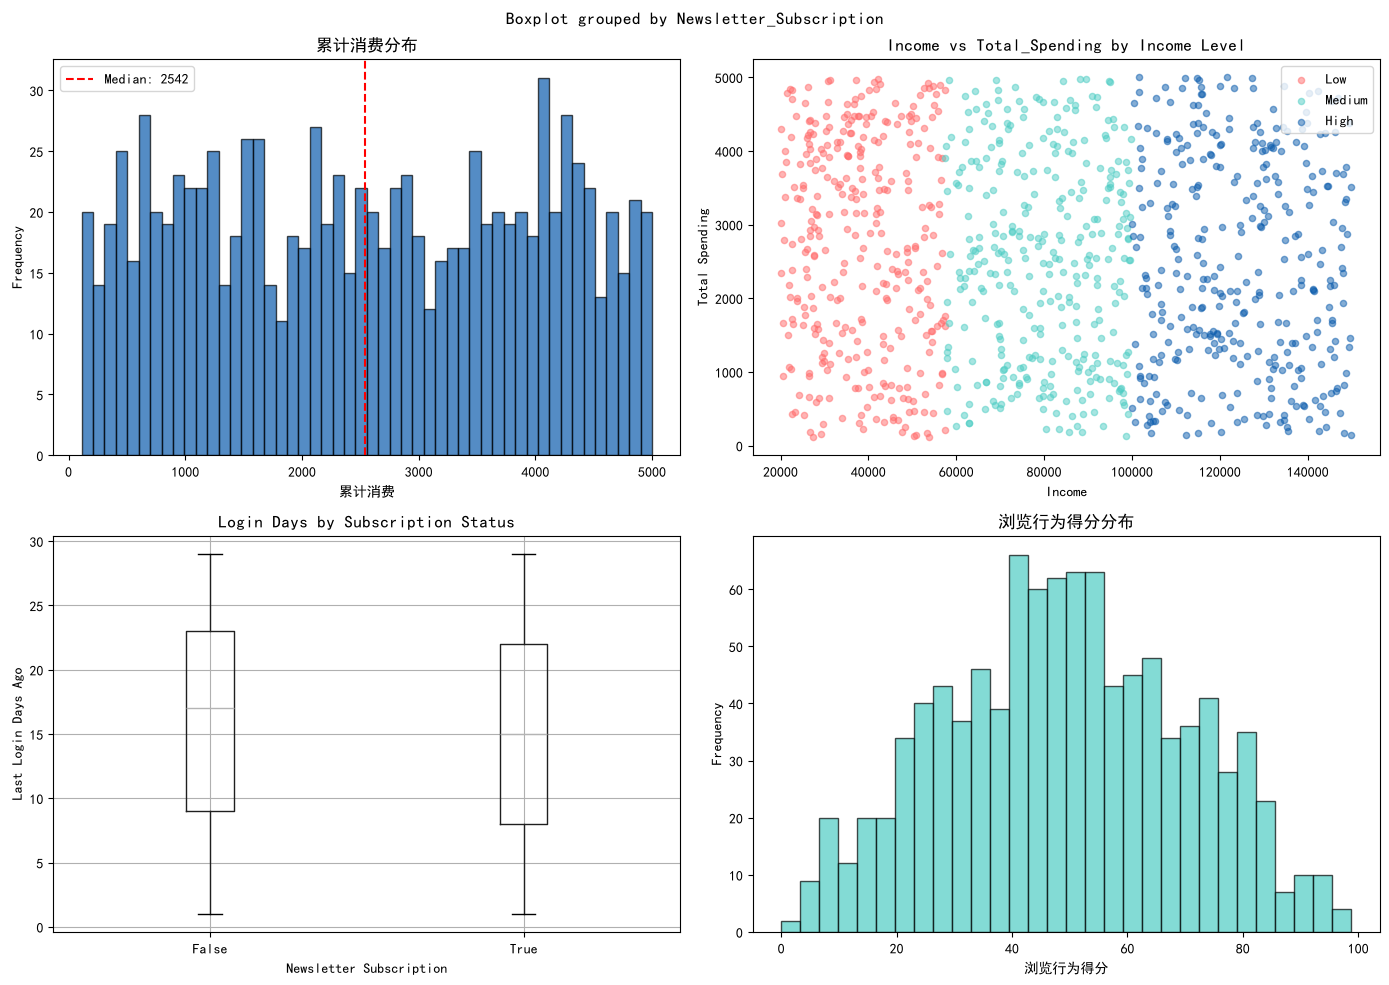

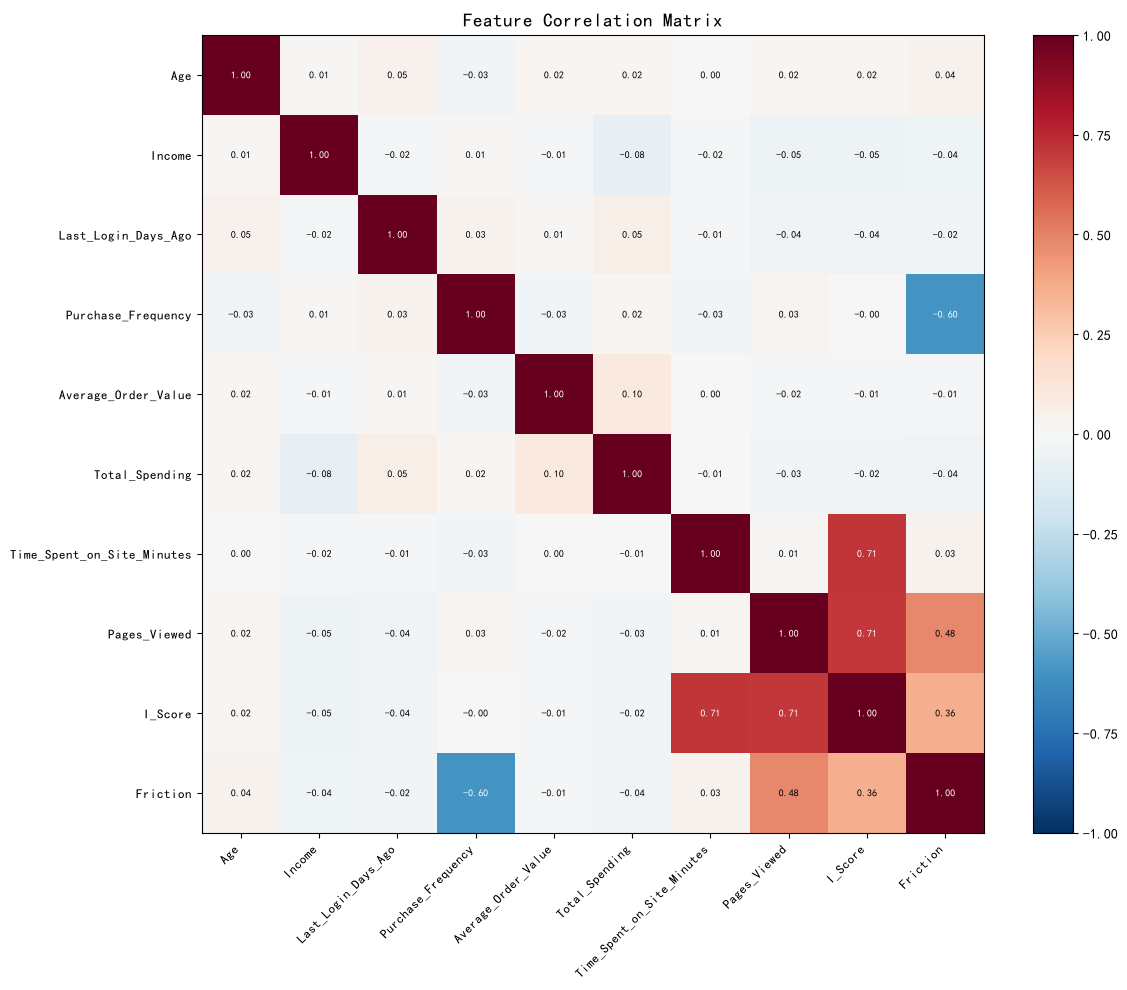


关键相关性分析:
Time_Spent vs Purchase_Frequency 相关系数: -0.028
Pages_Viewed vs Purchase_Frequency 相关系数: 0.026

高摩擦用户(前25%)特征:
  - 平均浏览页数: 34.3
  - 平均购买频率: 1.6
  - 平均消费金额: 2514

高收入低消费群体:
  - 用户数: 184
  - 占高收入群体比例: 54.1%


In [19]:
# 5. EDA探索性数据分析
def perform_eda(df, output_dir):
    """分析消费分布、相关性和用户特征"""
    
    print("\n" + "=" * 60)
    print("第三阶段：EDA探索性数据分析")
    print("=" * 60)
    
    # 1. 关键分布分析
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Total_Spending 分布
    axes[0, 0].hist(df['Total_Spending'], bins=50, edgecolor='black', alpha=0.7, color='#0B5CAD')
    axes[0, 0].set_title('累计消费分布', fontsize=12)
    axes[0, 0].set_xlabel('累计消费')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].axvline(df['Total_Spending'].median(), color='red', linestyle='--', 
                       label=f'Median: {df["Total_Spending"].median():.0f}')
    axes[0, 0].legend()
    
    # Income vs Total_Spending 散点图
    colors = {'Low': '#FF6B6B', 'Medium': '#4ECDC4', 'High': '#0B5CAD'}
    for level in ['Low', 'Medium', 'High']:
        subset = df[df['Income_Level'] == level]
        axes[0, 1].scatter(subset['Income'], subset['Total_Spending'], 
                          alpha=0.5, label=level, c=colors[level], s=20)
    axes[0, 1].set_title('Income vs Total_Spending by Income Level', fontsize=12)
    axes[0, 1].set_xlabel('Income')
    axes[0, 1].set_ylabel('Total Spending')
    axes[0, 1].legend()
    
    # Last_Login_Days_Ago vs Newsletter_Subscription 箱线图
    df.boxplot(column='Last_Login_Days_Ago', by='Newsletter_Subscription', ax=axes[1, 0])
    axes[1, 0].set_title('Login Days by Subscription Status', fontsize=12)
    axes[1, 0].set_xlabel('Newsletter Subscription')
    axes[1, 0].set_ylabel('Last Login Days Ago')
    
    # I_Score 分布
    axes[1, 1].hist(df['I_Score'], bins=30, edgecolor='black', alpha=0.7, color='#4ECDC4')
    axes[1, 1].set_title('浏览行为得分分布', fontsize=12)
    axes[1, 1].set_xlabel('浏览行为得分')
    axes[1, 1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/eda_distributions.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    # 2. 相关性分析
    numeric_cols = ['Age', 'Income', 'Last_Login_Days_Ago', 'Purchase_Frequency', 
                    'Average_Order_Value', 'Total_Spending', 'Time_Spent_on_Site_Minutes', 
                    'Pages_Viewed', 'I_Score', 'Friction']
    
    corr_matrix = df[numeric_cols].corr()
    
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(corr_matrix, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
    ax.set_xticks(range(len(numeric_cols)))
    ax.set_yticks(range(len(numeric_cols)))
    ax.set_xticklabels(numeric_cols, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(numeric_cols, fontsize=9)
    
    for i in range(len(numeric_cols)):
        for j in range(len(numeric_cols)):
            text = ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                          ha='center', va='center', fontsize=7,
                          color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black')
    
    ax.set_title('Feature Correlation Matrix', fontsize=14)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/correlation_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    # 3. 关键行为洞察
    time_purchase_corr = df['Time_Spent_on_Site_Minutes'].corr(df['Purchase_Frequency'])
    pages_purchase_corr = df['Pages_Viewed'].corr(df['Purchase_Frequency'])
    
    print(f"\n关键相关性分析:")
    print(f"Time_Spent vs Purchase_Frequency 相关系数: {time_purchase_corr:.3f}")
    print(f"Pages_Viewed vs Purchase_Frequency 相关系数: {pages_purchase_corr:.3f}")
    
    # 高摩擦用户分析
    high_friction = df[df['Friction'] > df['Friction'].quantile(0.75)]
    print(f"\n高摩擦用户(前25%)特征:")
    print(f"  - 平均浏览页数: {high_friction['Pages_Viewed'].mean():.1f}")
    print(f"  - 平均购买频率: {high_friction['Purchase_Frequency'].mean():.1f}")
    print(f"  - 平均消费金额: {high_friction['Total_Spending'].mean():.0f}")
    
    # 高收入低消费群体
    high_income_low_spend = df[(df['Income_Level'] == 'High') & 
                               (df['Total_Spending'] < df['Total_Spending'].median())]
    print(f"\n高收入低消费群体:")
    print(f"  - 用户数: {len(high_income_low_spend)}")
    print(f"  - 占高收入群体比例: {len(high_income_low_spend)/len(df[df['Income_Level']=='High'])*100:.1f}%")
    
    return {
        'time_purchase_corr': time_purchase_corr,
        'pages_purchase_corr': pages_purchase_corr,
        'high_friction_count': len(high_friction),
        'high_income_low_spend_count': len(high_income_low_spend)
    }

eda_results = perform_eda(df, output_dir)

In [20]:
# 6. RFM-I模型构建
def build_rfm_model(df):
    """计算 R、F、M 和综合得分"""
    
    print("\n" + "=" * 60)
    print("第四阶段：RFM-I模型构建")
    print("=" * 60)
    
    # 归一化函数
    def min_max_normalize(series, reverse=False):
        min_val, max_val = series.min(), series.max()
        if max_val == min_val:
            return pd.Series(50.0, index=series.index)
        if reverse:
            return ((max_val - series) / (max_val - min_val)) * 100
        return ((series - min_val) / (max_val - min_val)) * 100
    
    df['R_Score'] = min_max_normalize(df['Last_Login_Days_Ago'], reverse=True)
    df['F_Score'] = min_max_normalize(df['Purchase_Frequency'])
    df['M_Score'] = min_max_normalize(df['Total_Spending'])
    df['RFM_Score'] = 0.2 * df['R_Score'] + 0.3 * df['F_Score'] + 0.5 * df['M_Score']
    df['I_Weight'] = df['I_Score'] / 500  # I_Score 0-100 -> 0-0.2
    df['Final_Score'] = df['RFM_Score'] * (1 + df['I_Weight'])
    
    print(f"R_Score 范围: [{df['R_Score'].min():.2f}, {df['R_Score'].max():.2f}]")
    print(f"F_Score 范围: [{df['F_Score'].min():.2f}, {df['F_Score'].max():.2f}]")
    print(f"M_Score 范围: [{df['M_Score'].min():.2f}, {df['M_Score'].max():.2f}]")
    print(f"RFM_Score 范围: [{df['RFM_Score'].min():.2f}, {df['RFM_Score'].max():.2f}]")
    print(f"Final_Score 范围: [{df['Final_Score'].min():.2f}, {df['Final_Score'].max():.2f}]")
    
    return df

df = build_rfm_model(df)
df[['User_ID','R_Score','F_Score','M_Score','I_Score','RFM_Score','Final_Score']].head()


第四阶段：RFM-I模型构建
R_Score 范围: [0.00, 100.00]
F_Score 范围: [0.00, 100.00]
M_Score 范围: [0.00, 100.00]
RFM_Score 范围: [4.72, 96.77]
Final_Score 范围: [5.26, 105.06]


,User_ID,R_Score,F_Score,M_Score,I_Score,RFM_Score,Final_Score
0,#1,85.714286,77.777778,49.805607,87.285385,65.378994,76.792255
1,#2,50.000000,77.777778,4.256190,76.638400,35.461428,40.896843
2,#3,3.571429,11.111111,74.769797,25.460637,41.432518,43.542314
3,#4,39.285714,33.333333,87.272355,73.136516,61.493320,70.488135
4,#5,96.428571,55.555556,89.830162,13.646357,80.867462,83.074554


In [21]:
# 7. 用户分层与画像
# 保存原标签和展示名称
display_names = {
    '纠结土豪': '高收入高浏览低购买用户',
    '羊毛党/低值': '低收入低浏览低消费用户',
    '高潜流失客': '高收入消费较高低活跃用户',
}

def classify_users(df):
    """按 RFM、浏览行为和收入规则划分用户"""
    
    print("\n" + "=" * 60)
    print("第五阶段：用户分层与画像")
    print("=" * 60)
    
    def classify_user(row):
        r = row['R_Score']
        f = row['F_Score']
        m = row['M_Score']
        i = row['I_Score']
        income = row['Income_Level']
        friction = row['Friction']
        
        # 基础RFM分层逻辑
        if r > 60 and f > 60 and m > 60:
            base_label = "重要价值用户"
        elif r > 60 and m > 60 and f < 40:
            base_label = "重要发展用户"
        elif r < 40 and f > 60 and m > 60:
            base_label = "重要保持用户"
        elif r < 40 and m > 60:
            base_label = "重要挽留用户"
        elif r > 60 and f > 40 and m < 40:
            base_label = "一般发展用户"
        elif r > 60 and f < 40 and m < 40:
            base_label = "一般维持用户"
        elif r < 40 and f < 40 and m < 40:
            base_label = "低价值用户"
        else:
            base_label = "一般用户"
        
        # 浏览行为与收入细分
        if base_label in ["低价值用户", "一般维持用户"] and income == "High" and i > 60:
            return "高潜沉睡用户"
        if income == "High" and i > 70 and f < 40 and m < 50:
            return "纠结土豪"
        if base_label in ["一般维持用户", "一般发展用户"] and i > 80 and friction > df['Friction'].quantile(0.6):
            return "犹豫型潜力用户"
        if income == "Low" and i > 70 and f < 40:
            return "隐形活跃者"
        if income == "High" and r < 40 and m > 50:
            return "高潜流失客"
        if m > 70 and f > 70 and i > 60:
            return "核心VIP"
        if income == "Low" and i < 40 and m < 40:
            return "羊毛党/低值"
        
        return base_label
    
    df['User_Segment'] = df.apply(classify_user, axis=1)
    # 生成标签的展示名称
    df['Segment_Name'] = df['User_Segment'].replace(display_names)
    
    # 分层统计
    
    segment_stats = df.groupby('User_Segment').agg({
        'User_ID': 'count',
        'Total_Spending': 'mean',
        'Purchase_Frequency': 'mean',
        'I_Score': 'mean',
        'Income': 'mean',
        'Final_Score': 'mean'
    }).round(2)
    segment_stats.columns = [
        '用户数', '平均累计消费', '平均购买频率',
        '平均浏览得分', '平均收入', '平均综合分'
    ]
    segment_stats['占比(%)'] = (segment_stats['用户数'] / len(df) * 100).round(1)
    segment_stats = segment_stats.sort_values('用户数', ascending=False)
    
    print("\n用户分层统计:")
    print(segment_stats.rename(index=display_names).to_string())
    
    return df, segment_stats

df, segment_stats = classify_users(df)


第五阶段：用户分层与画像

用户分层统计:
              用户数   平均累计消费  平均购买频率  平均浏览得分       平均收入  平均综合分  占比(%)
User_Segment                                                       
一般用户          443  2368.12    5.17   48.80   84305.72  54.31   44.3
一般发展用户         81  1117.95    6.43   49.84   87107.43  52.67    8.1
重要挽留用户         67  4134.42    2.57   46.53   59698.61  58.59    6.7
高收入消费较高低活跃用户   64  3990.70    4.92   44.09  121985.09  65.40    6.4
低价值用户          50  1036.52    1.68   42.79   94734.76  20.87    5.0
重要发展用户         48  3873.96    1.62   48.91   81230.60  65.41    4.8
一般维持用户         47  1055.40    1.47   45.83   91335.23  33.57    4.7
重要价值用户         47  3960.19    7.47   42.28   73500.94  86.82    4.7
重要保持用户         39  4030.23    7.49   48.00   57995.92  75.26    3.9
隐形活跃者          34  2756.79    1.32   77.99   36273.32  47.28    3.4
低收入低浏览低消费用户    32  1019.56    5.50   23.08   37896.19  37.05    3.2
核心VIP          23  4171.39    8.17   71.09   59382.39  88.86    2.3
高潜沉睡用户         12  1318.1

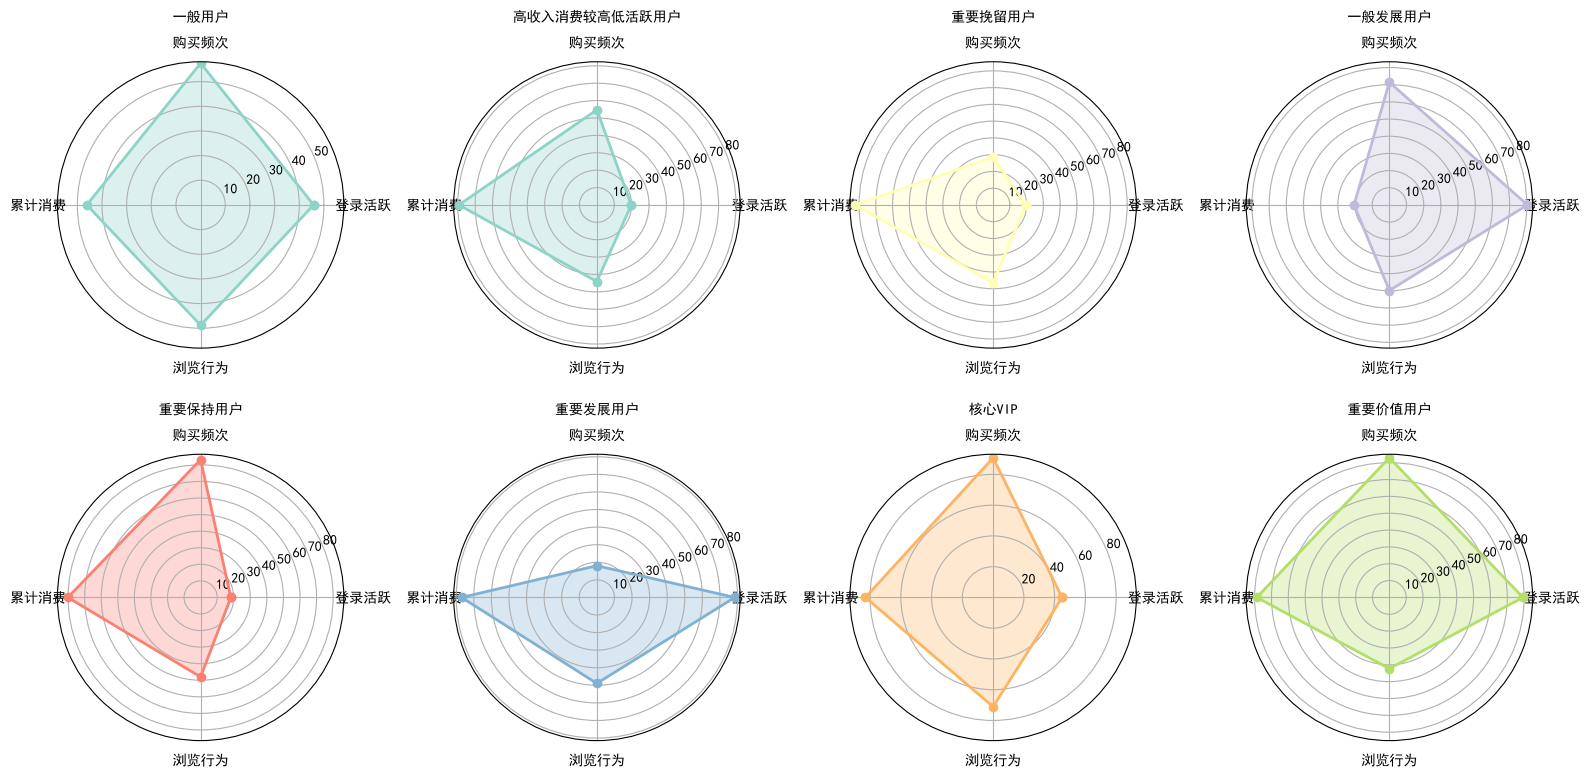

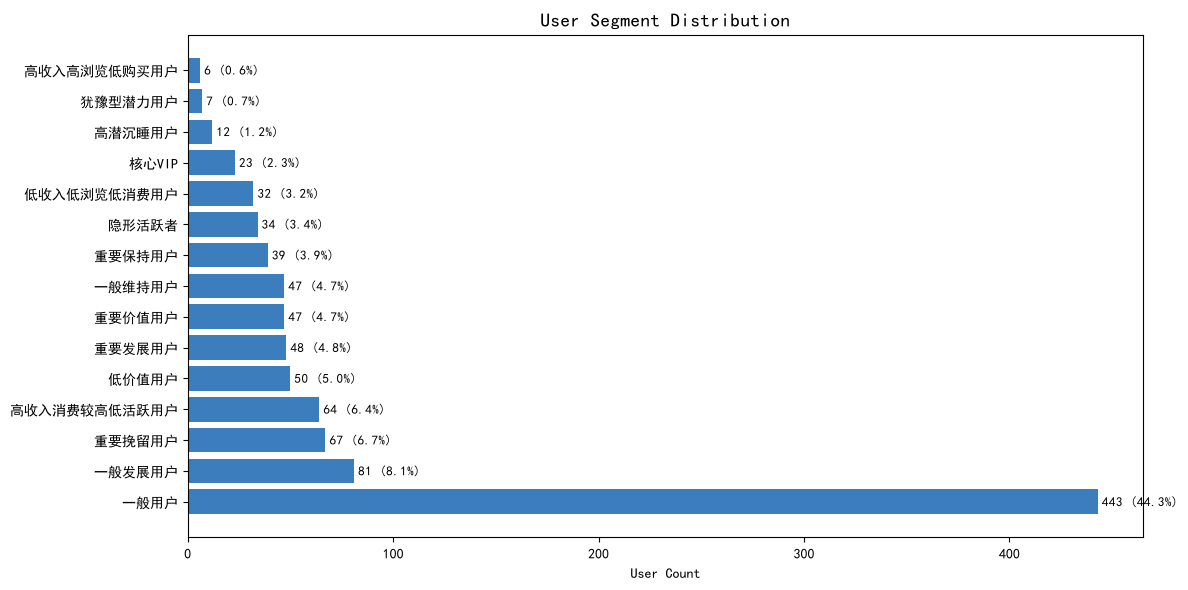

In [22]:
# 8. 生成用户画像可视化
def generate_segment_portrait(df, output_dir):
    """绘制用户画像和分层数量"""
    
    # 分层雷达图
    segments = df['Segment_Name'].unique()
    metrics = ['R_Score', 'F_Score', 'M_Score', 'I_Score']
    
    segment_means = df.groupby('Segment_Name')[metrics].mean()
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), subplot_kw=dict(polar=True))
    axes = axes.flatten()
    
    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
    angles += angles[:1]
    
    colors = plt.cm.Set3(np.linspace(0, 1, len(segments)))
    
    for idx, segment in enumerate(segments[:8]):
        if idx >= len(axes):
            break
        ax = axes[idx]
        values = segment_means.loc[segment].tolist()
        values += values[:1]
        
        ax.fill(angles, values, alpha=0.3, color=colors[idx])
        ax.plot(angles, values, 'o-', color=colors[idx], linewidth=2)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(
            ['登录活跃', '购买频次', '累计消费', '浏览行为'],
            fontsize=10
        )
        ax.set_title(segment, fontsize=10, pad=10)
    
    for idx in range(len(segments), len(axes)):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/segment_radar.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    # 分层分布柱状图
    segment_counts = df['Segment_Name'].value_counts()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.barh(segment_counts.index, segment_counts.values, color='#0B5CAD', alpha=0.8)
    ax.set_xlabel('User Count')
    ax.set_title('User Segment Distribution', fontsize=14)
    
    for bar, count in zip(bars, segment_counts.values):
        ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2, 
                f'{count} ({count/len(df)*100:.1f}%)', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/segment_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

generate_segment_portrait(df, output_dir)


第六阶段：ROI测算

【假设参数】
  总预算: 10000元
  优惠券成本: 10元/人
  平均客单价: 104元

【转化率假设】
  RFM前20%用户：自然转化率 20.0%，发券后 30.0%，边际提升 10.0%
  核心用户：自然转化率 25.0%，发券后 30.0%，边际提升 5.0%
  潜力用户：自然转化率 1.0%，发券后 20.0%，边际提升 19.0%

【方案A - 传统RFM策略】
  目标用户数: 200
  成本: 2000元
  边际收益（增量）: 2081元
  边际ROI: 4.0%

【方案B - 优化RFI策略】
  核心用户: 70
  新挖掘潜力用户: 89
  总目标用户数: 159
  实际成本: 1590元 (预算使用率: 15.9%)
  边际收益（增量）: 2123元
  边际ROI: 33.5%


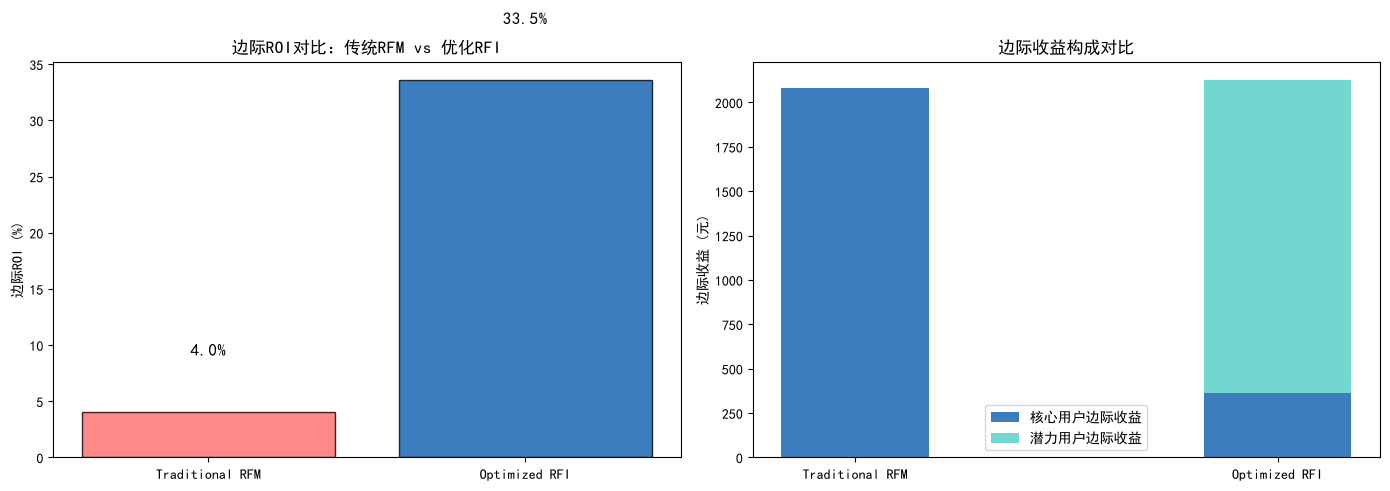

In [23]:
# 9. ROI测算
def calculate_roi(df, output_dir):
    """按初始参数比较两种选人策略的收益"""
    
    print("\n" + "=" * 60)
    print("第六阶段：ROI测算")
    print("=" * 60)
    
    # ================= 可调整参数=================
    total_budget = 10000          # 总预算（元）
    coupon_cost = 10               # 每张优惠券成本（元）
    aov = df['Average_Order_Value'].mean()  # 平均客单价（元）
    
    # 转化率设定
    # 核心用户
    core_natural = 0.25            # 核心用户无券自然转化率
    core_with_coupon = 0.30        # 核心用户发券后转化率
    # 潜力用户
    potential_natural = 0.01       # 潜力用户自然转化率
    potential_with_coupon = 0.20   # 潜力用户发券后转化率（可调高至20%-25%）
    # 一般用户（用于方案A的基线）
    general_natural = 0.02          # 一般用户自然转化率
    # RFM前20%用户的自然转化率（介于核心和一般之间）
    rfm20_natural = 0.20            # 可根据实际数据调整，例如：RFM高分用户通常转化率较高
    rfm20_with_coupon = 0.30        # 发券后转化率（通常不会超过核心用户）
    
    # 边际提升
    core_lift = core_with_coupon - core_natural
    potential_lift = potential_with_coupon - potential_natural
    rfm20_lift = rfm20_with_coupon - rfm20_natural
    
    # ================= 方案A：传统RFM策略 =================
    top20_threshold = df['RFM_Score'].quantile(0.80)
    rfm_top20 = df[df['RFM_Score'] >= top20_threshold]
    target_a_count = min(len(rfm_top20), total_budget // coupon_cost)
    cost_a = target_a_count * coupon_cost
    
    incremental_revenue_a = target_a_count * rfm20_lift * aov
    roi_a = (incremental_revenue_a - cost_a) / cost_a * 100 if cost_a > 0 else 0
    
    # ================= 方案B：优化RFI策略 =================
    core_users = df[df['User_Segment'].isin(['核心VIP', '重要价值用户'])]
    potential_users = df[df['User_Segment'].isin(['纠结土豪', '高潜沉睡用户', '犹豫型潜力用户', '高潜流失客'])]
    
    # 分配预算：优先核心用户（用80%预算），剩余给潜力用户
    core_count = min(len(core_users), int(total_budget * 0.8 / coupon_cost))
    remaining_budget = total_budget - core_count * coupon_cost
    potential_count = min(len(potential_users), remaining_budget // coupon_cost)
    target_b_count = core_count + potential_count
    cost_b = target_b_count * coupon_cost
    
    incremental_revenue_b = core_count * core_lift * aov + potential_count * potential_lift * aov
    roi_b = (incremental_revenue_b - cost_b) / cost_b * 100 if cost_b > 0 else 0
    
    # ================= 输出结果 =================
    print(f"\n【假设参数】")
    print(f"  总预算: {total_budget}元")
    print(f"  优惠券成本: {coupon_cost}元/人")
    print(f"  平均客单价: {aov:.0f}元")
    
    print(f"\n【转化率假设】")
    print(f"  RFM前20%用户：自然转化率 {rfm20_natural*100:.1f}%，发券后 {rfm20_with_coupon*100:.1f}%，边际提升 {rfm20_lift*100:.1f}%")
    print(f"  核心用户：自然转化率 {core_natural*100:.1f}%，发券后 {core_with_coupon*100:.1f}%，边际提升 {core_lift*100:.1f}%")
    print(f"  潜力用户：自然转化率 {potential_natural*100:.1f}%，发券后 {potential_with_coupon*100:.1f}%，边际提升 {potential_lift*100:.1f}%")
    
    print(f"\n【方案A - 传统RFM策略】")
    print(f"  目标用户数: {target_a_count}")
    print(f"  成本: {cost_a}元")
    print(f"  边际收益（增量）: {incremental_revenue_a:.0f}元")
    print(f"  边际ROI: {roi_a:.1f}%")
    
    print(f"\n【方案B - 优化RFI策略】")
    print(f"  核心用户: {core_count}")
    print(f"  新挖掘潜力用户: {potential_count}")
    print(f"  总目标用户数: {target_b_count}")
    print(f"  实际成本: {cost_b}元 (预算使用率: {cost_b/total_budget*100:.1f}%)")
    print(f"  边际收益（增量）: {incremental_revenue_b:.0f}元")
    print(f"  边际ROI: {roi_b:.1f}%")
    
    # ROI对比可视化
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 边际ROI对比
    strategies = ['Traditional RFM', 'Optimized RFI']
    rois = [roi_a, roi_b]
    colors = ['#FF6B6B', '#0B5CAD']
    
    bars = axes[0].bar(strategies, rois, color=colors, alpha=0.8, edgecolor='black')
    axes[0].set_ylabel('边际ROI (%)')
    axes[0].set_title('边际ROI对比：传统RFM vs 优化RFI', fontsize=12)
    for bar, roi in zip(bars, rois):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
                    f'{roi:.1f}%', ha='center', fontsize=12, fontweight='bold')
    
    # 边际收益构成对比
    x = np.arange(2)
    width = 0.35
    
    core_marginal = [incremental_revenue_a, core_count * core_lift * aov]
    potential_marginal = [0, potential_count * potential_lift * aov]
    
    axes[1].bar(x, core_marginal, width, label='核心用户边际收益', color='#0B5CAD', alpha=0.8)
    axes[1].bar(x, potential_marginal, width, bottom=core_marginal, label='潜力用户边际收益', color='#4ECDC4', alpha=0.8)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(strategies)
    axes[1].set_ylabel('边际收益 (元)')
    axes[1].set_title('边际收益构成对比', fontsize=12)
    axes[1].legend()
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/roi_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    return {
        'strategy_a': {
            'target_count': int(target_a_count),
            'cost': cost_a,
            'incremental_revenue': incremental_revenue_a,
            'marginal_roi': roi_a
        },
        'strategy_b': {
            'core_count': int(core_count),
            'potential_count': int(potential_count),
            'total_count': int(target_b_count),
            'actual_cost': cost_b,
            'budget_used_ratio': cost_b/total_budget,
            'incremental_revenue': incremental_revenue_b,
            'marginal_roi': roi_b
        },
        'params': {
            'budget': total_budget,
            'coupon_cost': coupon_cost,
            'aov': aov,
            'rfm20_lift': rfm20_lift,
            'core_lift': core_lift,
            'potential_lift': potential_lift
        }
    }
roi_results = calculate_roi(df, output_dir)

## 10. 保存全量分层结果

保存全量 1,000 人的得分、标签和分层汇总。用户明细写入 `user_segments.csv`，分层统计分别按原标签和展示名称保存。


In [24]:
df.to_csv(output_dir / 'user_segments.csv', index=False, encoding='utf-8-sig')
segment_stats.to_csv(output_dir / 'segment_stats.csv', encoding='utf-8-sig')
print('已导出用户分层表和分层汇总表')

# 按展示名称保存汇总表
segment_stats.rename(index=display_names).to_csv(
    output_dir / 'segment_display_stats.csv', encoding='utf-8-sig'
)


已导出用户分层表和分层汇总表


## 11. 排除 85 人后重新分层

排除购买频次为 0、累计消费大于 0 的 85 名用户，对剩余 915 人重新计算特征、得分和分层。


全量用户数 1000
本轮排除人数 85
本轮保留人数 915

第二阶段：特征工程 - 构建优化指标
I_Score 范围: [0.00, 98.83]
Friction 范围: [0.10, 24.50]
L_Score 分布: {1: 756, 3: 91, 2: 68}
Income_Level 分布: {'High': 311, 'Low': 302, 'Medium': 302}

第四阶段：RFM-I模型构建
R_Score 范围: [0.00, 100.00]
F_Score 范围: [0.00, 100.00]
M_Score 范围: [0.00, 100.00]
RFM_Score 范围: [1.39, 96.77]
Final_Score 范围: [1.55, 105.06]

第五阶段：用户分层与画像

用户分层统计:
              用户数   平均累计消费  平均购买频率  平均浏览得分       平均收入  平均综合分  占比(%)
User_Segment                                                       
一般用户          396  2350.41    5.52   48.84   84960.75  53.61   43.3
一般发展用户         67  1157.87    6.94   50.84   87814.24  54.09    7.3
高收入消费较高低活跃用户   57  3979.33    5.53   45.18  122478.79  65.89    6.2
重要挽留用户         54  4151.80    3.11   45.75   58676.33  57.84    5.9
低价值用户          53  1046.89    2.42   41.12   93069.89  20.42    5.8
重要发展用户         48  3864.25    2.38   50.14   76650.46  65.61    5.2
一般维持用户         47  1011.49    2.57   44.02   95589.23  34.09    5.1
重要价值用户     

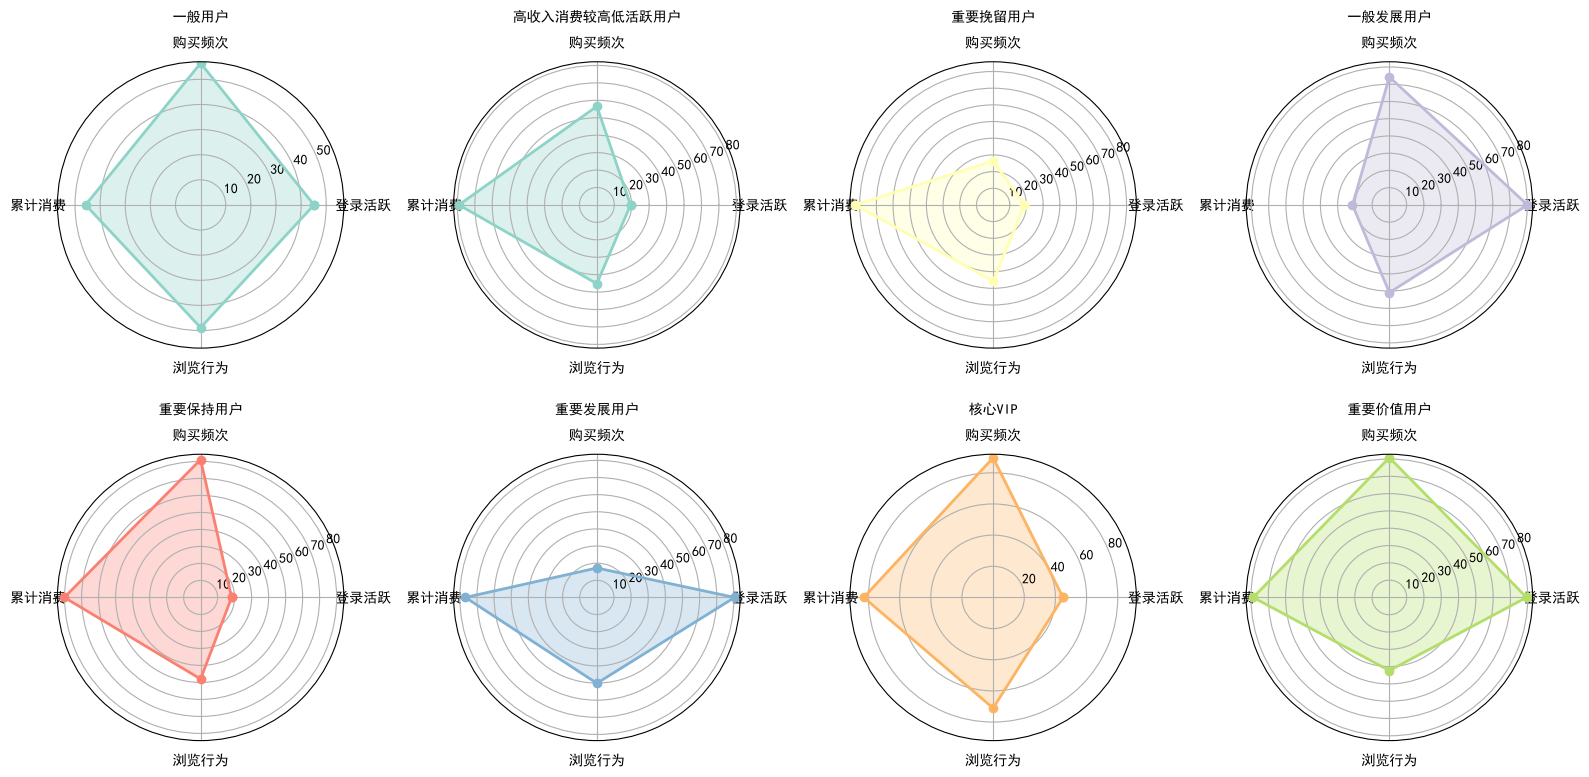

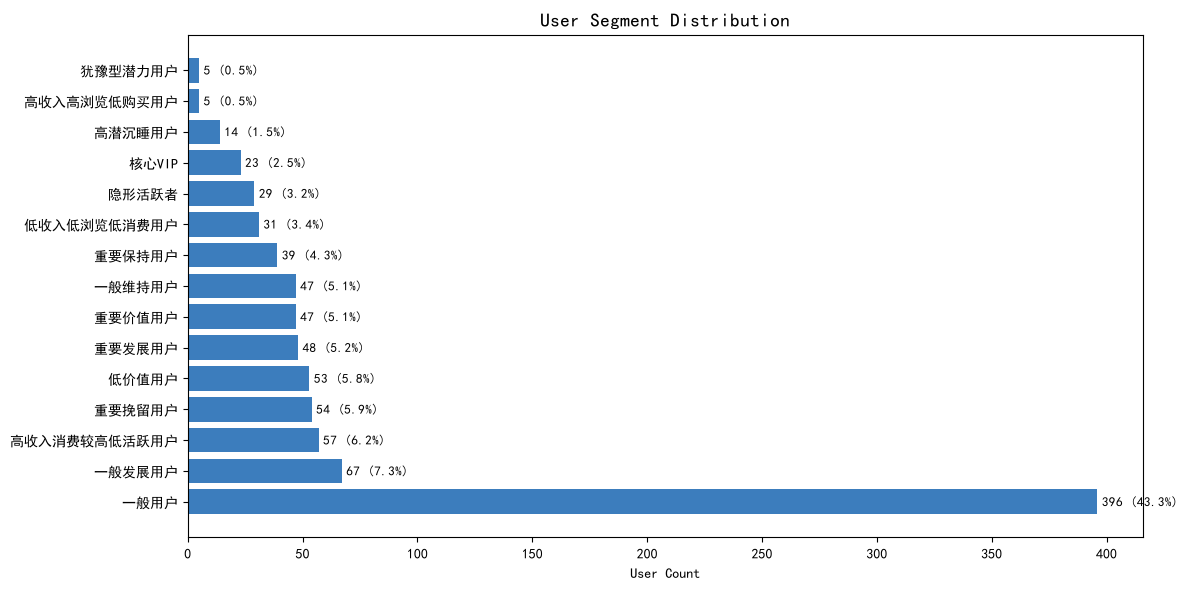

In [25]:
# 排除后的结果目录
review_dir = output_dir / 'exclude_85'
review_dir.mkdir(parents=True, exist_ok=True)

# 保留未标记的用户
reviewed_df = raw_df.loc[~raw_df['Needs_Review']].copy()
print('全量用户数', len(raw_df))
print('本轮排除人数', int(raw_df['Needs_Review'].sum()))
print('本轮保留人数', len(reviewed_df))

# 重新计算特征、得分与分层
reviewed_df = feature_engineering(reviewed_df)
reviewed_df = build_rfm_model(reviewed_df)
reviewed_df, reviewed_stats = classify_users(reviewed_df)

# 保存重算结果
generate_segment_portrait(reviewed_df, review_dir)
reviewed_df.to_csv(review_dir / 'user_segments.csv', index=False, encoding='utf-8-sig')
reviewed_stats.to_csv(review_dir / 'segment_stats.csv', encoding='utf-8-sig')
reviewed_stats.rename(index=display_names).to_csv(
    review_dir / 'segment_display_stats.csv', encoding='utf-8-sig'
)


## 12. 比较分层结果

比较排除前后的样本概况、各类用户数量和标签变化。在共同保留的 915 人中，43 人的标签发生变化，下表列出对应用户及其前后得分。


In [26]:
# 排除前后的样本概况
quality_comparison = pd.DataFrame({
    '样本': ['全量样本', '排除标记记录后'],
    '用户数': [len(df), len(reviewed_df)],
    '待核对人数': [int(df['Needs_Review'].sum()), int(reviewed_df['Needs_Review'].sum())],
    '平均累计消费': [df['Total_Spending'].mean(), reviewed_df['Total_Spending'].mean()],
    '平均浏览得分': [df['I_Score'].mean(), reviewed_df['I_Score'].mean()],
}).round(2)
display(quality_comparison)

# 比较同一批用户的前后标签
retained_original = df.loc[~df['Needs_Review']]
segment_comparison = pd.DataFrame({
    '全量人数': df['User_Segment'].value_counts(),
    '保留用户_原评分人数': retained_original['User_Segment'].value_counts(),
    '保留用户_重新评分人数': reviewed_df['User_Segment'].value_counts(),
}).fillna(0).astype(int)
segment_comparison['全量占比(%)'] = (
    segment_comparison['全量人数'] / len(df) * 100
).round(1)
segment_comparison['排除后占比(%)'] = (
    segment_comparison['保留用户_重新评分人数'] / len(reviewed_df) * 100
).round(1)
segment_comparison['重新评分带来的人数变化'] = (
    segment_comparison['保留用户_重新评分人数']
    - segment_comparison['保留用户_原评分人数']
)
segment_comparison.insert(
    0, '展示名称', segment_comparison.index.to_series().replace(display_names)
)
segment_comparison = segment_comparison.sort_values('全量人数', ascending=False)
display(segment_comparison)

# 按用户 ID 匹配前后标签与得分
user_comparison = retained_original[[
    'User_ID', 'User_Segment', 'Final_Score'
]].rename(columns={
    'User_Segment': '原分层', 'Final_Score': '原综合分'
}).merge(
    reviewed_df[['User_ID', 'User_Segment', 'Final_Score']].rename(columns={
        'User_Segment': '新分层', 'Final_Score': '新综合分'
    }),
    on='User_ID', how='inner', validate='one_to_one'
)
user_comparison['标签发生变化'] = user_comparison['原分层'] != user_comparison['新分层']
user_comparison['综合分变化'] = user_comparison['新综合分'] - user_comparison['原综合分']
label_changes = user_comparison.loc[user_comparison['标签发生变化']].copy()
print('共同用户数', len(user_comparison))
print('其中标签变化人数', len(label_changes))
display(label_changes)

# 保存样本概况、分层对比和标签变化名单
quality_comparison.to_csv(output_dir / 'quality_comparison.csv', index=False, encoding='utf-8-sig')
segment_comparison.to_csv(output_dir / 'segment_comparison.csv', encoding='utf-8-sig')
user_comparison.to_csv(output_dir / 'user_comparison.csv', index=False, encoding='utf-8-sig')
label_changes.to_csv(output_dir / 'label_changes.csv', index=False, encoding='utf-8-sig')


,样本,用户数,待核对人数,平均累计消费,平均浏览得分
0,全量样本,1000,85,2552.96,49.12
1,排除标记记录后,915,0,2542.17,49.03


,展示名称,全量人数,保留用户_原评分人数,保留用户_重新评分人数,全量占比(%),排除后占比(%),重新评分带来的人数变化
User_Segment,,,,,,,
一般用户,一般用户,443,423,396,44.3,43.3,-27
一般发展用户,一般发展用户,81,81,67,8.1,7.3,-14
重要挽留用户,重要挽留用户,67,55,54,6.7,5.9,-1
高潜流失客,高收入消费较高低活跃用户,64,57,57,6.4,6.2,0
低价值用户,低价值用户,50,42,53,5.0,5.8,11
重要发展用户,重要发展用户,48,39,48,4.8,5.2,9
一般维持用户,一般维持用户,47,34,47,4.7,5.1,13
重要价值用户,重要价值用户,47,47,47,4.7,5.1,0
重要保持用户,重要保持用户,39,39,39,3.9,4.3,0


共同用户数 915
其中标签变化人数 43


,User_ID,原分层,原综合分,新分层,新综合分,标签发生变化,综合分变化
24,#25,一般用户,57.541682,隐形活跃者,55.147507,True,-2.394176
44,#47,一般发展用户,44.220748,一般维持用户,41.931611,True,-2.289137
49,#53,一般用户,29.029848,高潜沉睡用户,26.588038,True,-2.441810
65,#71,一般发展用户,50.211101,一般维持用户,47.921070,True,-2.290031
78,#85,一般发展用户,38.092464,一般维持用户,35.888498,True,-2.203967
82,#89,一般用户,30.377705,低价值用户,28.040759,True,-2.336945
112,#123,一般用户,75.862598,重要发展用户,73.614705,True,-2.247893
124,#141,一般用户,74.960186,重要发展用户,72.580841,True,-2.379345
128,#145,一般用户,34.575423,低价值用户,32.378959,True,-2.196464
135,#153,一般用户,85.275197,重要发展用户,82.935482,True,-2.339715


## 13. 比较目标名单

将核心 VIP、重要价值用户和四类潜力用户合并为目标人群。全量样本选出 159 人，移除待核对记录后剩余 147 人；重新评分后新增 4 人，最终为 151 人。


In [27]:
# 筛选核心与潜力用户
target_labels = [
    '核心VIP', '重要价值用户', '纠结土豪',
    '高潜沉睡用户', '犹豫型潜力用户', '高潜流失客'
]
full_target_ids = set(df.loc[df['User_Segment'].isin(target_labels), 'User_ID'])
review_target_ids = set(
    reviewed_df.loc[reviewed_df['User_Segment'].isin(target_labels), 'User_ID']
)
marked_ids = set(raw_df.loc[raw_df['Needs_Review'], 'User_ID'])
retained_target_ids = full_target_ids - marked_ids

target_comparison = pd.DataFrame({
    '指标': [
        '全量分析目标人数',
        '原目标中被质量标记排除的人数',
        '保留用户按原评分入选人数',
        '保留用户重算后入选人数',
        '共同保留的目标用户数',
        '保留用户重算后离开目标人数',
        '保留用户重算后新进入目标人数',
    ],
    '人数': [
        len(full_target_ids),
        len(full_target_ids & marked_ids),
        len(retained_target_ids),
        len(review_target_ids),
        len(retained_target_ids & review_target_ids),
        len(retained_target_ids - review_target_ids),
        len(review_target_ids - retained_target_ids),
    ],
})
display(target_comparison)

# 保存目标名单变化明细
target_membership = df[['User_ID', 'Needs_Review', 'User_Segment']].rename(
    columns={'User_Segment': '原分层'}
).merge(
    reviewed_df[['User_ID', 'User_Segment']].rename(columns={'User_Segment': '新分层'}),
    on='User_ID', how='left', validate='one_to_one'
)
target_membership['原目标成员'] = target_membership['User_ID'].isin(full_target_ids)
target_membership['新目标成员'] = target_membership['User_ID'].isin(review_target_ids)
target_changes = target_membership.loc[
    target_membership['原目标成员'] != target_membership['新目标成员']
].copy()
display(target_changes)

target_comparison.to_csv(output_dir / 'target_comparison.csv', index=False, encoding='utf-8-sig')
target_changes.to_csv(output_dir / 'target_changes.csv', index=False, encoding='utf-8-sig')
print('全部结果保存在', output_dir)


,指标,人数
0,全量分析目标人数,159
1,原目标中被质量标记排除的人数,12
2,保留用户按原评分入选人数,147
3,保留用户重算后入选人数,151
4,共同保留的目标用户数,147
5,保留用户重算后离开目标人数,0
6,保留用户重算后新进入目标人数,4


,User_ID,Needs_Review,原分层,新分层,原目标成员,新目标成员
52,#53,False,一般用户,高潜沉睡用户,False,True
66,#67,True,高潜流失客,NaN,True,False
94,#95,True,高潜流失客,NaN,True,False
139,#140,True,纠结土豪,NaN,True,False
309,#310,True,高潜沉睡用户,NaN,True,False
395,#396,True,高潜沉睡用户,NaN,True,False
530,#531,True,高潜流失客,NaN,True,False
541,#542,True,高潜流失客,NaN,True,False
544,#545,True,高潜流失客,NaN,True,False
593,#594,True,高潜流失客,NaN,True,False


全部结果保存在 C:\Users\86156\Documents\ChatGPT\sql\电商用户分层项目_跟做包\outputs\improved
